# Model development and experiments (week 3)

This notebook continues `Classification.ipynb` (week 2: cleaning, preprocessing, baselines).
We try new models, tune them with grid search, handle the class imbalance, test feature selection
and ensembles, then compare everything with the logistic regression baseline.

Rules we follow (same as week 2):

- All experiments use the **training set only** (1069 lots), with the same 5-fold stratified cross-validation.
- Every fitted step (imputer, scaler, encoder, SMOTE, feature selector) is **inside the pipeline**,
  so it is fitted again on each fold.
- The **test set is used once**, at the end, for the final model only.
- Main metric: **macro F1**. We also report balanced accuracy, accuracy and the recall of
  `Commercial` (the costliest error for a buyer is a sub-grade lot predicted as `Specialty`).

In [1]:
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate, cross_val_predict)
from sklearn.metrics import (make_scorer, recall_score, f1_score, classification_report,
                             ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (RandomForestClassifier, HistGradientBoostingClassifier,
                              BaggingClassifier, VotingClassifier, StackingClassifier)
from sklearn.feature_selection import SelectKBest, f_classif, RFE, SelectFromModel
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

## Data and split

We load the clean file written by `Classification.ipynb`. We redo the **same** `train_test_split` call
(same seed, same row order), so we get exactly the same training and test lots in the same order,
and the cross-validation folds are the same as in week 2. The `assert` checks that our split
matches the `split` column saved in the file.

In [2]:
df = pd.read_csv("./../dataset/coffee_clean.csv")

TARGET = "quality_class"
NUM_COLS = ["harvest_year", "grading_year", "altitude_mean_meters", "moisture_percentage",
            "category_one_defects", "category_two_defects"]
CAT_COLS = ["country_of_origin", "region", "variety", "processing_method", "color"]

CLASS_ORDER = ["Commercial / Sub-Grade (<80)", "Specialty (80-84)", "Exemplary (85+)"]
CLASS_SHORT = ["Commercial", "Specialty", "Exemplary"]
COMMERCIAL = CLASS_ORDER[0]

X = df[NUM_COLS + CAT_COLS]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)
assert (df.loc[X_train.index, "split"] == "train").all()
assert (df.loc[X_test.index, "split"] == "test").all()
print(f"train: {len(X_train)} lots, test: {len(X_test)} lots")

train: 1069 lots, test: 268 lots


## Preprocessing pipeline

Same preprocessing as in week 2 (copied from `Classification.ipynb`):
median imputation + missing indicator + scaling for numeric columns,
`"Unknown"` + one-hot encoding (rare categories grouped) for text columns.

Tree models do not need scaling, but scaling does not change their splits, so we keep one
preprocessing for all models. This makes the comparison fair: only the classifier changes.

In [3]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)),
])
preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

## Evaluation protocol

**Metrics.** We add the `Commercial` recall to the week 2 metrics. With one label in `labels`,
`recall_score(..., average="macro")` returns the recall of this class only.

**Pipeline.** We use the `Pipeline` of `imblearn` instead of the one of scikit-learn. It works the
same way, but it also accepts resampling steps like SMOTE. A resampling step only runs during `fit`
(on the training folds), never during `predict`, so the validation folds are never resampled.

**Nested cross-validation.** When we tune a model with `GridSearchCV`, its `best_score_` is too
optimistic: the same folds are used to choose the hyperparameters and to score them. So we put the
grid search *inside* each fold of the outer cross-validation:

- outer loop: the same 5 folds as the baselines; the outer validation fold is used only to score;
- inner loop: `GridSearchCV` chooses the hyperparameters on the 4 other folds (5-fold CV again).

The score of a tuned model is then an honest estimate of "model + tuning procedure", and it can be
compared with the baselines on the same folds. We also print the hyperparameters chosen in each
outer fold: if they change a lot, the tuning is not stable.

In [4]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

SCORING = {
    "F1 macro": "f1_macro",
    "Balanced accuracy": "balanced_accuracy",
    "Accuracy": "accuracy",
    "Commercial recall": make_scorer(recall_score, labels=[COMMERCIAL], average="macro"),
}

results = {}  # model name -> scores of the 5 outer folds, for each metric


def make_model(clf, select=None, smote=False):
    # preprocessing -> (feature selection) -> (SMOTE) -> classifier
    steps = [("preprocess", clone(preprocess))]
    if select is not None:
        steps.append(("select", select))
    if smote:
        steps.append(("smote", SMOTE(random_state=42)))
    steps.append(("clf", clf))
    return Pipeline(steps)


def evaluate(name, model, param_grid=None):
    # 5-fold CV on the training set; with a param_grid, the grid search runs inside each fold (nested CV)
    if param_grid is not None:
        model = GridSearchCV(model, param_grid, scoring="f1_macro", cv=cv, n_jobs=-1)
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=SCORING,
                            return_estimator=param_grid is not None)
    results[name] = {metric: scores[f"test_{metric}"] for metric in SCORING}
    if param_grid is not None:
        for fold, search in enumerate(scores["estimator"]):
            print(f"fold {fold}: {search.best_params_}")
    return summary([name])


def summary(names=None):
    # table "mean ± std" over the 5 folds
    names = names or list(results)
    return pd.DataFrame({
        name: {metric: f"{s.mean():.3f} ± {s.std():.3f}" for metric, s in results[name].items()}
        for name in names
    }).T

## Baselines (week 2)

We evaluate the two baselines again with the same folds, to have their `Commercial` recall and
their score on each fold (needed to compare models fold by fold).

In [5]:
evaluate("Dummy (most frequent)", make_model(DummyClassifier(strategy="most_frequent")))
evaluate("Logistic regression (baseline)", make_model(LogisticRegression(class_weight="balanced", max_iter=2000)))
summary()

,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Dummy (most frequent),0.293 ± 0.000,0.333 ± 0.000,0.782 ± 0.002,0.000 ± 0.000
Logistic regression (baseline),0.457 ± 0.028,0.602 ± 0.051,0.540 ± 0.030,0.635 ± 0.049


## 1. Grid search on the baseline

We tune the logistic regression:

- `C`: inverse of the regularization strength (small `C` = simpler model).
- `l1_ratio`: type of penalty, `0` = L2 (shrinks all coefficients), `1` = L1 (sets some coefficients
  to zero, so it also selects features). In scikit-learn 1.9 the old `penalty` parameter is deprecated;
  `l1_ratio` replaces it.
- The `saga` solver is the only one that supports L1 for a multi-class problem.

We avoid the traps of LAB 6: the grid search uses 5 stratified folds (not 2), the macro F1
(not accuracy), and never sees the test set.

In [6]:
lr_grid = {
    "clf__C": [0.01, 0.1, 1, 10],
    "clf__l1_ratio": [0, 1],
}
evaluate("Logistic regression (tuned)",
         make_model(LogisticRegression(class_weight="balanced", solver="saga", max_iter=10000, random_state=42)),
         lr_grid)

fold 0: {'clf__C': 0.1, 'clf__l1_ratio': 0}
fold 1: {'clf__C': 0.1, 'clf__l1_ratio': 0}
fold 2: {'clf__C': 0.1, 'clf__l1_ratio': 0}
fold 3: {'clf__C': 0.01, 'clf__l1_ratio': 0}
fold 4: {'clf__C': 0.1, 'clf__l1_ratio': 0}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Logistic regression (tuned),0.455 ± 0.028,0.591 ± 0.027,0.542 ± 0.044,0.621 ± 0.054


The grid search almost always chooses `C = 0.1` with the L2 penalty, but the score does not change
(0.455 against 0.457). The baseline was already close to the best a linear model can do with these
features: tuning the regularization does not help, the limit is the model family.

## 2. Tree-based models

- **Decision tree**: easy to read, but one tree has a high variance.
- **Random forest**: many deep trees on bootstrap samples and random subsets of features
  (bagging), then a vote. It reduces the variance of a single tree.
- **Histogram gradient boosting**: small trees added one after the other, each one corrects the errors
  of the previous ones (boosting). It mainly reduces the bias.

All three use `class_weight="balanced"`, like the baseline. Trees can learn interactions
(for example country × altitude) that a linear model cannot.

In [7]:
tree_grid = {
    "clf__max_depth": [3, 5, 8, None],
    "clf__min_samples_leaf": [1, 5, 20],
}
evaluate("Decision tree",
         make_model(DecisionTreeClassifier(class_weight="balanced", random_state=42)),
         tree_grid)

fold 0: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 1: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 2: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 3: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 4: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Decision tree,0.468 ± 0.016,0.464 ± 0.009,0.708 ± 0.019,0.297 ± 0.046


In [8]:
rf_grid = {
    "clf__max_depth": [5, 10, None],
    "clf__min_samples_leaf": [1, 5, 10],
}
evaluate("Random forest",
         make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
         rf_grid)

fold 0: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 1: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1}
fold 2: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 3: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}
fold 4: {'clf__max_depth': None, 'clf__min_samples_leaf': 1}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Random forest,0.539 ± 0.050,0.571 ± 0.051,0.707 ± 0.050,0.560 ± 0.122


In [9]:
hgb_grid = {
    "clf__learning_rate": [0.03, 0.1],
    "clf__max_depth": [3, None],
    "clf__min_samples_leaf": [10, 20],
}
evaluate("Gradient boosting (HGB)",
         make_model(HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
         hgb_grid)

fold 0: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__min_samples_leaf': 20}
fold 1: {'clf__learning_rate': 0.03, 'clf__max_depth': None, 'clf__min_samples_leaf': 10}
fold 2: {'clf__learning_rate': 0.03, 'clf__max_depth': None, 'clf__min_samples_leaf': 10}
fold 3: {'clf__learning_rate': 0.1, 'clf__max_depth': None, 'clf__min_samples_leaf': 10}
fold 4: {'clf__learning_rate': 0.03, 'clf__max_depth': None, 'clf__min_samples_leaf': 10}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Gradient boosting (HGB),0.498 ± 0.016,0.509 ± 0.028,0.705 ± 0.020,0.439 ± 0.049


- **Decision tree**: the grid search chooses the deepest tree (`max_depth=None`, `min_samples_leaf=1`)
  in all 5 folds. Its macro F1 is about the same as the baseline (0.47), but its balanced accuracy is
  much lower (0.46) and it finds only 30 % of the `Commercial` lots: it predicts `Specialty` most of the time.
- **Random forest**: the best model of this section, macro F1 **0.54 ± 0.05**, clearly above the
  baseline (0.46). The chosen hyperparameters are stable (deep trees in 4 folds out of 5). Its
  `Commercial` recall (0.56) is lower than the baseline (0.64): it makes fewer false alarms but also misses more
  bad lots. We look at this trade-off in section 7.
- **Gradient boosting**: 0.50, between the two. The chosen `learning_rate` changes from fold to fold, so
  this tuning is not very stable.
- For the tree and the forest, the best values are at the edge of the grid (`None`, `1`). We did not extend
  the grid further: `None` and `1` are already the largest trees possible.

## 3. SVM and k-nearest neighbors

- **SVM** (LAB 6, exercise 2): `C` controls the margin, `kernel` is linear or RBF,
  `gamma` is the width of the RBF kernel. It also has `class_weight="balanced"`.
- **k-NN** has no `class_weight`: with 78 % of `Specialty`, most neighbours of any lot are `Specialty`.
  So we add SMOTE before it (see section 4). `n_neighbors` is the number of neighbours, `weights="distance"`
  gives more weight to the closest ones.

In [10]:
svm_grid = {
    "clf__C": [0.1, 1, 10],
    "clf__kernel": ["linear", "rbf"],
    "clf__gamma": ["scale", "auto"],
}
evaluate("SVM",
         make_model(SVC(class_weight="balanced", random_state=42)),
         svm_grid)

fold 0: {'clf__C': 1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
fold 1: {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}
fold 2: {'clf__C': 1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
fold 3: {'clf__C': 0.1, 'clf__gamma': 'auto', 'clf__kernel': 'rbf'}
fold 4: {'clf__C': 10, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
SVM,0.468 ± 0.027,0.552 ± 0.069,0.615 ± 0.041,0.518 ± 0.148


In [11]:
knn_grid = {
    "clf__n_neighbors": [5, 15, 31],
    "clf__weights": ["uniform", "distance"],
}
evaluate("k-NN + SMOTE", make_model(KNeighborsClassifier(), smote=True), knn_grid)

fold 0: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
fold 1: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
fold 2: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
fold 3: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}
fold 4: {'clf__n_neighbors': 5, 'clf__weights': 'distance'}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
k-NN + SMOTE,0.476 ± 0.034,0.578 ± 0.061,0.589 ± 0.031,0.601 ± 0.126


Both models are only slightly better than the baseline (0.47 and 0.48). The SVM hyperparameters
change in every fold (`C` from 0.1 to 10): the score surface is flat, no setting is clearly better.
k-NN always chooses the smallest number of neighbours in the grid (5) with `weights="distance"`:
only the very closest lots help. We did not check why; one hypothesis is that with 72 mostly one-hot
columns, the distance between two lots mainly says whether they share the same country, region and variety.

## 4. Class imbalance: class weights or SMOTE?

Two ways to give more importance to the rare classes:

- **Class weights** (used so far): the errors on rare classes cost more in the loss function.
- **SMOTE**: creates new synthetic lots of the rare classes, by interpolation between a lot and one of
  its nearest neighbours of the same class. It is a pipeline step, so it only runs on the training folds:
  the validation fold keeps its real class distribution.

Limitation: SMOTE runs after the one-hot encoding, so a synthetic lot can have values like 0.4 for
"country = Ethiopia". This is not a real lot. `SMOTENC` handles categorical columns, but it needs
the data before encoding and without missing values, which makes the pipeline more complex.
We compare SMOTE (without class weights) with class weights, for the logistic regression and the random forest.

In [12]:
evaluate("Logistic regression + SMOTE",
         make_model(LogisticRegression(solver="saga", max_iter=10000, random_state=42), smote=True),
         {"clf__C": [0.01, 0.1, 1, 10]})

fold 0: {'clf__C': 0.01}
fold 1: {'clf__C': 0.01}
fold 2: {'clf__C': 0.1}
fold 3: {'clf__C': 0.1}
fold 4: {'clf__C': 0.01}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Logistic regression + SMOTE,0.455 ± 0.021,0.588 ± 0.039,0.544 ± 0.031,0.655 ± 0.080


In [13]:
evaluate("Random forest + SMOTE",
         make_model(RandomForestClassifier(n_estimators=300, random_state=42), smote=True),
         rf_grid)

fold 0: {'clf__max_depth': 5, 'clf__min_samples_leaf': 1}
fold 1: {'clf__max_depth': None, 'clf__min_samples_leaf': 5}
fold 2: {'clf__max_depth': 10, 'clf__min_samples_leaf': 5}
fold 3: {'clf__max_depth': 10, 'clf__min_samples_leaf': 10}
fold 4: {'clf__max_depth': None, 'clf__min_samples_leaf': 5}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Random forest + SMOTE,0.544 ± 0.059,0.572 ± 0.071,0.713 ± 0.038,0.514 ± 0.120


SMOTE gives the same macro F1 as class weights (logistic regression: 0.455 against 0.457; random forest:
0.544 against 0.539, a difference far below the standard deviation of 0.05). With the forest, the
chosen hyperparameters become unstable (a different pair in almost every fold). So SMOTE adds a step,
creates unrealistic lots, and brings nothing measurable: we keep class weights.

## 5. Feature selection (Cheng 2024)

After one-hot encoding we have 72 columns for 1069 lots. We test the three families of
feature selection methods, each as a pipeline step placed after the preprocessing
(so it is fitted on the training folds only), with the logistic regression as classifier:

- **Filter** — `SelectKBest(f_classif)`: keeps the `k` columns with the highest ANOVA F-score
  (difference of the class means compared to the variance inside the classes). It looks at each column
  alone. The F-test assumes normal data with equal variances in each class; this is false for the
  0/1 one-hot columns and the skewed defect counts, so we only use the F-score to *rank* columns, not as a
  significance test. The cross-validation tells us if the ranking is useful.
- **Wrapper** — `RFE`: fits the logistic regression, removes the 5 columns with the smallest
  coefficients, and repeats until `n_features_to_select` columns are left.
- **Embedded** — `SelectFromModel` with an L1 logistic regression: L1 sets some coefficients
  to zero; we keep the columns with a non-zero coefficient. Its `C` controls how many columns are kept.

In [14]:
lr = LogisticRegression(class_weight="balanced", max_iter=2000)

evaluate("Filter: SelectKBest + LR",
         make_model(lr, select=SelectKBest(f_classif)),
         {"select__k": [10, 20, 40, "all"], "clf__C": [0.1, 1]})

fold 0: {'clf__C': 0.1, 'select__k': 20}
fold 1: {'clf__C': 0.1, 'select__k': 40}
fold 2: {'clf__C': 0.1, 'select__k': 'all'}
fold 3: {'clf__C': 0.1, 'select__k': 20}
fold 4: {'clf__C': 0.1, 'select__k': 40}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Filter: SelectKBest + LR,0.457 ± 0.039,0.609 ± 0.049,0.535 ± 0.052,0.669 ± 0.063


In [15]:
evaluate("Wrapper: RFE + LR",
         make_model(lr, select=RFE(LogisticRegression(class_weight="balanced", max_iter=2000), step=5)),
         {"select__n_features_to_select": [10, 20, 40], "clf__C": [0.1, 1]})

fold 0: {'clf__C': 0.1, 'select__n_features_to_select': 40}
fold 1: {'clf__C': 1, 'select__n_features_to_select': 10}
fold 2: {'clf__C': 0.1, 'select__n_features_to_select': 40}
fold 3: {'clf__C': 1, 'select__n_features_to_select': 40}
fold 4: {'clf__C': 0.1, 'select__n_features_to_select': 40}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Wrapper: RFE + LR,0.433 ± 0.010,0.558 ± 0.047,0.529 ± 0.038,0.635 ± 0.055


In [16]:
# max_iter=50000: with 10000, saga did not converge on one inner fold, and the selected columns changed
l1_selector = SelectFromModel(LogisticRegression(class_weight="balanced", solver="saga", l1_ratio=1,
                                                 max_iter=50000, random_state=42))

evaluate("Embedded: L1 selection + LR",
         make_model(lr, select=l1_selector),
         {"select__estimator__C": [0.05, 0.1, 0.5], "clf__C": [0.1, 1]})

fold 0: {'clf__C': 0.1, 'select__estimator__C': 0.5}
fold 1: {'clf__C': 0.1, 'select__estimator__C': 0.5}
fold 2: {'clf__C': 0.1, 'select__estimator__C': 0.1}
fold 3: {'clf__C': 0.1, 'select__estimator__C': 0.5}
fold 4: {'clf__C': 0.1, 'select__estimator__C': 0.5}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Embedded: L1 selection + LR,0.451 ± 0.033,0.593 ± 0.044,0.532 ± 0.040,0.642 ± 0.072


No selection method beats the baseline (filter 0.457, wrapper 0.433, embedded 0.451). The filter keeps
between 20 columns and all of them depending on the fold, and the embedded method keeps a large set
(`C = 0.5` in 4 folds). 72 columns for 1069 lots is not a high-dimensional problem, and the logistic
regression is already regularized (`C = 0.1` is chosen almost every time), so removing columns does not help.
The wrapper is the worst, and its chosen number of columns jumps between 10 and 40: RFE removes columns
5 at a time based on the size of the coefficients, which is a greedy choice and can drop columns that
are only useful together (we did not verify this on our data).

## 6. Ensembles

- **Bagging** of decision trees (LAB 6, exercise 3): each tree is trained on a bootstrap sample.
  We tune `n_estimators` (number of trees) and `max_samples` (size of each sample).
- **Voting**: the logistic regression, the random forest and the gradient boosting vote.
  `hard` = majority vote of the predicted classes; `soft` = average of the predicted probabilities.
- **Stacking**: a final logistic regression learns how to combine the probabilities of the same 3
  models. These probabilities come from an internal 5-fold CV, so the final model never sees
  predictions made on the lots used to train the base models.

For voting and stacking we keep the **default** hyperparameters of the 3 models (we only set
`class_weight="balanced"`, and 300 trees for the forest). If we used the values found by the grid searches
above, they would have been chosen on the same folds, and the score would be a bit optimistic.

In [17]:
evaluate("Bagging (decision trees)",
         make_model(BaggingClassifier(DecisionTreeClassifier(class_weight="balanced", random_state=42), random_state=42)),
         {"clf__n_estimators": [50, 200], "clf__max_samples": [0.5, 1.0]})

fold 0: {'clf__max_samples': 1.0, 'clf__n_estimators': 200}
fold 1: {'clf__max_samples': 1.0, 'clf__n_estimators': 50}
fold 2: {'clf__max_samples': 1.0, 'clf__n_estimators': 50}
fold 3: {'clf__max_samples': 1.0, 'clf__n_estimators': 50}
fold 4: {'clf__max_samples': 1.0, 'clf__n_estimators': 50}


,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Bagging (decision trees),0.485 ± 0.036,0.456 ± 0.028,0.773 ± 0.014,0.217 ± 0.060


In [18]:
base_models = [
    ("lr", LogisticRegression(class_weight="balanced", max_iter=2000)),
    ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
    ("hgb", HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
]

evaluate("Voting (hard)", make_model(VotingClassifier(base_models, voting="hard")))
evaluate("Voting (soft)", make_model(VotingClassifier(base_models, voting="soft")))
evaluate("Stacking", make_model(StackingClassifier(
    base_models, final_estimator=LogisticRegression(class_weight="balanced", max_iter=2000))))
summary(["Voting (hard)", "Voting (soft)", "Stacking"])

,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Voting (hard),0.543 ± 0.042,0.571 ± 0.052,0.717 ± 0.031,0.554 ± 0.109
Voting (soft),0.539 ± 0.043,0.559 ± 0.054,0.717 ± 0.025,0.500 ± 0.093
Stacking,0.454 ± 0.027,0.592 ± 0.049,0.542 ± 0.035,0.662 ± 0.046


- **Bagging of trees** (0.49) has the highest accuracy (0.77) but finds only 22 % of the `Commercial` lots,
  like the single deep tree. Averaging many trees reduces the variance, but each tree still mostly predicts
  `Specialty`. The random forest also chooses a random subset of columns at each split, and it does better
  (0.54); this is the main difference between the two.
- **Voting** (0.54) is as good as the random forest alone, not better: the forest and the gradient boosting
  make similar errors, so there is little to gain by combining them.
- **Stacking** (0.45) goes back to the level of the logistic regression. The final logistic regression uses
  `class_weight="balanced"`, so, like the baseline, it predicts the rare classes often (`Commercial` recall 0.66)
  at the cost of many `Specialty` errors (accuracy 0.54).

## 7. Comparison of all models

All scores below come from the same 5 outer folds of the training set.

In [19]:
table = summary()
table["_mean"] = [results[name]["F1 macro"].mean() for name in table.index]
table = table.sort_values("_mean", ascending=False).drop(columns="_mean")
table

,F1 macro,Balanced accuracy,Accuracy,Commercial recall
Random forest + SMOTE,0.544 ± 0.059,0.572 ± 0.071,0.713 ± 0.038,0.514 ± 0.120
Voting (hard),0.543 ± 0.042,0.571 ± 0.052,0.717 ± 0.031,0.554 ± 0.109
Random forest,0.539 ± 0.050,0.571 ± 0.051,0.707 ± 0.050,0.560 ± 0.122
Voting (soft),0.539 ± 0.043,0.559 ± 0.054,0.717 ± 0.025,0.500 ± 0.093
Gradient boosting (HGB),0.498 ± 0.016,0.509 ± 0.028,0.705 ± 0.020,0.439 ± 0.049
Bagging (decision trees),0.485 ± 0.036,0.456 ± 0.028,0.773 ± 0.014,0.217 ± 0.060
k-NN + SMOTE,0.476 ± 0.034,0.578 ± 0.061,0.589 ± 0.031,0.601 ± 0.126
Decision tree,0.468 ± 0.016,0.464 ± 0.009,0.708 ± 0.019,0.297 ± 0.046
SVM,0.468 ± 0.027,0.552 ± 0.069,0.615 ± 0.041,0.518 ± 0.148
Logistic regression (baseline),0.457 ± 0.028,0.602 ± 0.051,0.540 ± 0.030,0.635 ± 0.049


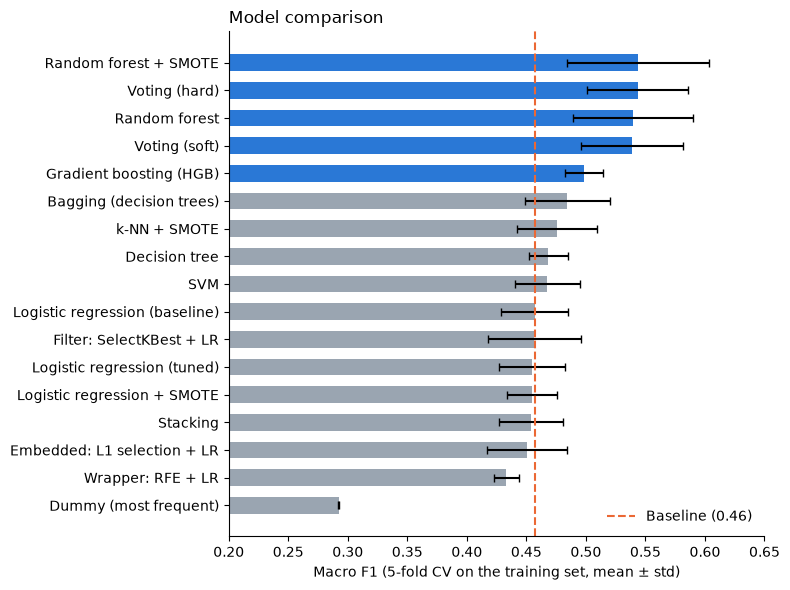

In [20]:
names = list(table.index)[::-1]  # best model at the top of the plot
means = [results[n]["F1 macro"].mean() for n in names]
stds = [results[n]["F1 macro"].std() for n in names]
baseline_f1 = results["Logistic regression (baseline)"]["F1 macro"].mean()

fig, ax = plt.subplots(figsize=(8, 6))
# blue: more than 0.03 (one standard deviation of the baseline) above the baseline
colors = ["#2a78d6" if m > baseline_f1 + 0.03 else "#9aa5b1" for m in means]
ax.barh(names, means, xerr=stds, color=colors, height=0.6, capsize=3)
ax.axvline(baseline_f1, color="#eb6834", linestyle="--", label=f"Baseline ({baseline_f1:.2f})")
ax.set_xlim(0.2, 0.65)
ax.set_xlabel("Macro F1 (5-fold CV on the training set, mean ± std)")
ax.set_title("Model comparison", loc="left")
ax.legend(loc="lower right", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("./../report/figures/model_comparison.pdf")
plt.show()

### Where does the gain come from?

The macro F1 is a mean over the 3 classes. To see which class improves, we compare the out-of-fold
predictions of the baseline and of the random forest on the training set (`cross_val_predict`,
same folds: each lot is predicted by a model that did not see it). The random forest uses the
hyperparameters chosen most often by its nested grid search above.

=== Logistic regression (baseline)
              precision    recall  f1-score   support

  Commercial       0.28      0.64      0.39       148
   Specialty       0.87      0.51      0.64       836
   Exemplary       0.23      0.66      0.34        85

    accuracy                           0.54      1069
   macro avg       0.46      0.60      0.46      1069
weighted avg       0.73      0.54      0.58      1069

=== Random forest
              precision    recall  f1-score   support

  Commercial       0.40      0.51      0.45       148
   Specialty       0.84      0.79      0.82       836
   Exemplary       0.34      0.36      0.35        85

    accuracy                           0.72      1069
   macro avg       0.53      0.56      0.54      1069
weighted avg       0.74      0.72      0.73      1069



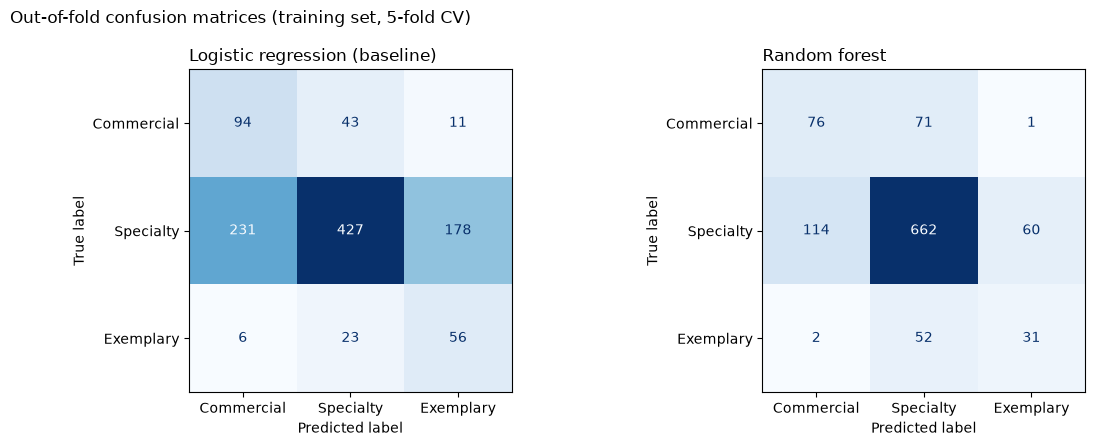

In [21]:
rf_model = make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42))
lr_model = make_model(LogisticRegression(class_weight="balanced", max_iter=2000))

oof = {
    "Logistic regression (baseline)": cross_val_predict(lr_model, X_train, y_train, cv=cv),
    "Random forest": cross_val_predict(rf_model, X_train, y_train, cv=cv),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, y_oof) in zip(axes, oof.items()):
    print(f"=== {name}")
    print(classification_report(y_train, y_oof, labels=CLASS_ORDER, target_names=CLASS_SHORT, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_train, y_oof, labels=CLASS_ORDER, display_labels=CLASS_SHORT,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, loc="left")
fig.suptitle("Out-of-fold confusion matrices (training set, 5-fold CV)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("./../report/figures/oof_confusion.pdf")
plt.show()

**Reading.** Four models reach about 0.54 (random forest, random forest + SMOTE, hard and soft voting); their
differences (< 0.01) are much smaller than the fold standard deviation (≈ 0.05), so we cannot rank them.
The gain over the baseline does **not** come from the rare classes:

- `Specialty`: F1 goes from 0.64 to 0.82. The baseline sends half of the `Specialty` lots to the other classes
  (recall 0.51); the forest keeps 79 % of them.
- `Commercial`: F1 goes from 0.39 to 0.45. Precision improves (0.28 → 0.40) but recall drops (0.64 → 0.51).
- `Exemplary`: F1 stays the same (0.34 → 0.35). Recall drops from 0.66 to 0.36: the forest finds fewer
  great lots, but its alerts are more often right (precision 0.23 → 0.34).

So the forest is a better *general* classifier, but a buyer who wants to catch every bad lot or every great
lot would still prefer the baseline. In our problem definition we said that a lower `Commercial` recall
must be discussed, not accepted automatically: here it is the price of far fewer false alarms
(the baseline flags 331 lots as `Commercial` to find 94 of them; the forest flags 192 to find 76).
The forest also almost never mixes up the two extremes (1 `Commercial` lot predicted `Exemplary`,
2 `Exemplary` lots predicted `Commercial`, against 11 and 6 for the baseline): most of its errors are
between neighbouring classes, where the cup scores are only a few points apart.

## 8. Is the gain significant?

The 5 fold scores are not enough to compare two models: the folds share most of their training lots,
so the scores are **not independent**, and a classic paired t-test is too optimistic
(it underestimates the variance). We use the **corrected resampled t-test** of Nadeau and Bengio (2003):

- 5-fold CV repeated 10 times with different shuffles → 50 paired differences $d_j$ (random forest − baseline);
- $t = \bar d \,/\, \sqrt{(1/J + n_{val}/n_{train})\, s_d^2}$, with $J = 50$ and $n_{val}/n_{train} = 1/4$;
  the term $n_{val}/n_{train}$ corrects for the overlap between training sets; $J - 1$ degrees of freedom.

Assumption: the differences are roughly normal. We check it with a Shapiro–Wilk test.
Fallback if normality is rejected: a Wilcoxon signed-rank test on the 10 per-repetition mean
differences (no normality needed, but the repetitions still share data, so the p-value stays approximate).
For comparison, we also print the naive paired t-test.

In [22]:
repeated_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)

f1_lr = cross_validate(lr_model, X_train, y_train, cv=repeated_cv, scoring="f1_macro", n_jobs=-1)["test_score"]
f1_rf = cross_validate(rf_model, X_train, y_train, cv=repeated_cv, scoring="f1_macro", n_jobs=-1)["test_score"]

d = f1_rf - f1_lr
J = len(d)
ratio = 1 / 4  # n_val / n_train for 5-fold CV
t_corr = d.mean() / np.sqrt((1 / J + ratio) * d.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=J - 1)
half_width = stats.t.ppf(0.975, df=J - 1) * np.sqrt((1 / J + ratio) * d.var(ddof=1))

print(f"Baseline:      {f1_lr.mean():.3f} ± {f1_lr.std():.3f}")
print(f"Random forest: {f1_rf.mean():.3f} ± {f1_rf.std():.3f}")
print(f"Difference:    {d.mean():.3f}, 95% CI (corrected) [{d.mean() - half_width:.3f}, {d.mean() + half_width:.3f}]")
print(f"Corrected t-test: t = {t_corr:.2f}, p = {p_corr:.1e}")
print(f"Naive paired t-test (too optimistic): p = {stats.ttest_rel(f1_rf, f1_lr).pvalue:.1e}")
print(f"Shapiro-Wilk on the differences: p = {stats.shapiro(d).pvalue:.2f}")
print(f"Fallback, Wilcoxon on the 10 repetition means: p = {stats.wilcoxon(d.reshape(10, 5).mean(axis=1)).pvalue:.1e}")

Baseline:      0.448 ± 0.037
Random forest: 0.541 ± 0.050
Difference:    0.093, 95% CI (corrected) [0.053, 0.134]
Corrected t-test: t = 4.61, p = 2.9e-05
Naive paired t-test (too optimistic): p = 4.0e-22
Shapiro-Wilk on the differences: p = 0.39
Fallback, Wilcoxon on the 10 repetition means: p = 2.0e-03


The random forest is better than the baseline by **0.09 macro F1**, with a corrected 95 % confidence interval
of about [0.05, 0.13] and p ≈ 3·10⁻⁵. Shapiro–Wilk does not reject normality (p = 0.39), so the t-test
can be used; the Wilcoxon fallback agrees (all 10 repetitions favour the forest). The naive t-test gives
p ≈ 10⁻²², which shows how much it overstates the evidence when the folds are not independent.

Limit: the forest's hyperparameters here are the ones the nested grid search chose most often, so they
were chosen on the same training data; the difference may be slightly optimistic. The nested CV result
(0.539 against 0.457, section 2) does not have this bias and gives the same conclusion.

## 9. Cost and interpretability

LAB 6 asks to compare the models on more than the score. Each model below is trained on the whole
training set with default or most often chosen hyperparameters; the prediction time is measured on the 1069 training lots.
The size is the size of the saved pipeline (`pickle`).

In [23]:
cost_models = {
    "Logistic regression (baseline)": lr_model,
    "Decision tree": make_model(DecisionTreeClassifier(class_weight="balanced", random_state=42)),
    "SVM": make_model(SVC(class_weight="balanced", random_state=42)),
    "Random forest": rf_model,
    "Gradient boosting (HGB)": make_model(HistGradientBoostingClassifier(class_weight="balanced", random_state=42)),
    "Voting (hard)": make_model(VotingClassifier(base_models, voting="hard")),
}
interpretability = {
    "Logistic regression (baseline)": "high (one coefficient per feature and class)",
    "Decision tree": "high if shallow (rules)",
    "SVM": "low (RBF kernel)",
    "Random forest": "medium (feature importance only)",
    "Gradient boosting (HGB)": "medium (feature importance only)",
    "Voting (hard)": "low (3 models)",
}

rows = {}
for name, model in cost_models.items():
    model = clone(model)
    start = time.perf_counter()
    model.fit(X_train, y_train)
    fit_time = time.perf_counter() - start
    start = time.perf_counter()
    model.predict(X_train)
    predict_time = time.perf_counter() - start
    rows[name] = {
        "Fit time (s)": round(fit_time, 2),
        "Predict time (ms)": round(predict_time * 1000, 1),
        "Size (kB)": round(len(pickle.dumps(model)) / 1000),
        "Interpretability": interpretability[name],
    }
pd.DataFrame(rows).T

,Fit time (s),Predict time (ms),Size (kB),Interpretability
Logistic regression (baseline),0.02,5.0,18,high (one coefficient per feature and class)
Decision tree,0.02,5.0,76,high if shallow (rules)
SVM,0.06,62.3,582,low (RBF kernel)
Random forest,0.25,30.7,15386,medium (feature importance only)
Gradient boosting (HGB),0.33,11.6,1083,medium (feature importance only)
Voting (hard),0.62,41.9,16457,low (3 models)


All models are fast enough for our use (a buyer scores a few lots, not millions). The main difference is the
size: the random forest (300 deep trees) and the voting are about 15 MB, against 18 kB for the logistic
regression. The times are measured once, so they are only orders of magnitude.

## 10. Final model and test set

**Choice, based on cross-validation only.** Four models are tied at about 0.54 macro F1 (section 7).
We choose the **random forest with class weights**: it is a single model (the voting needs 3), it does not
create synthetic lots (unlike SMOTE), and its gain over the baseline is significant (section 8).

We refit its grid search on the whole training set, then we evaluate it **once** on the test set.
The grid search may choose other hyperparameters than in sections 7–8 (where we used the deepest trees,
the most frequent choice): this is the same procedure that was scored in the nested CV.

The test set has only 268 lots (21 `Exemplary`), so one test score is noisy. We add a 95 % bootstrap
confidence interval: we draw 2000 samples of 268 test lots with replacement and compute the macro F1
on each. Assumption: the test lots are independent draws from the same distribution as future lots.

In [24]:
final_search = GridSearchCV(
    make_model(RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42)),
    rf_grid, scoring="f1_macro", cv=cv, n_jobs=-1,
)
final_search.fit(X_train, y_train)
final_model = final_search.best_estimator_
print("Hyperparameters chosen on the training set:", final_search.best_params_)

Hyperparameters chosen on the training set: {'clf__max_depth': 10, 'clf__min_samples_leaf': 1}


=== Logistic regression (baseline): macro F1 = 0.515 (95% CI [0.446, 0.583])
              precision    recall  f1-score   support

  Commercial       0.33      0.78      0.46        37
   Specialty       0.92      0.56      0.70       210
   Exemplary       0.27      0.67      0.38        21

    accuracy                           0.60       268
   macro avg       0.51      0.67      0.52       268
weighted avg       0.79      0.60      0.64       268



=== Random forest (final): macro F1 = 0.634 (95% CI [0.550, 0.709])
              precision    recall  f1-score   support

  Commercial       0.44      0.68      0.53        37
   Specialty       0.90      0.79      0.84       210
   Exemplary       0.46      0.62      0.53        21

    accuracy                           0.76       268
   macro avg       0.60      0.69      0.63       268
weighted avg       0.80      0.76      0.77       268



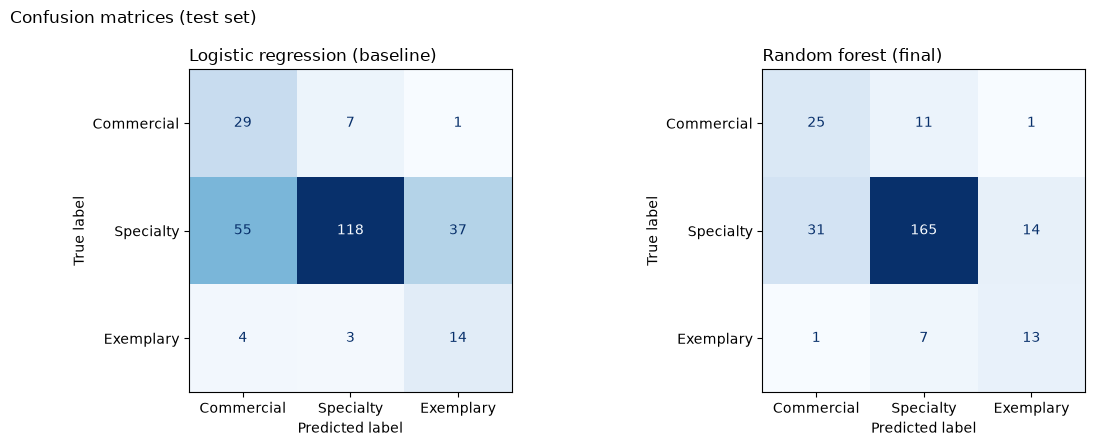

In [25]:
def bootstrap_f1(y_true, y_pred, n_boot=2000, seed=42):
    # 95% percentile bootstrap interval of the macro F1
    rng = np.random.default_rng(seed)
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        scores.append(f1_score(y_true[idx], y_pred[idx], average="macro"))
    return np.percentile(scores, [2.5, 97.5])


test_preds = {
    "Logistic regression (baseline)": clone(lr_model).fit(X_train, y_train).predict(X_test),
    "Random forest (final)": final_model.predict(X_test),
}

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (name, y_pred) in zip(axes, test_preds.items()):
    low, high = bootstrap_f1(y_test, y_pred)
    print(f"=== {name}: macro F1 = {f1_score(y_test, y_pred, average='macro'):.3f} (95% CI [{low:.3f}, {high:.3f}])")
    print(classification_report(y_test, y_pred, labels=CLASS_ORDER, target_names=CLASS_SHORT, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASS_ORDER, display_labels=CLASS_SHORT,
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(name, loc="left")
fig.suptitle("Confusion matrices (test set)", x=0.01, ha="left")
plt.tight_layout()
plt.savefig("./../report/figures/test_confusion.pdf")
plt.show()

- On the test set the random forest gets **0.63** macro F1 (95 % bootstrap CI [0.55, 0.71]), against 0.52
  ([0.45, 0.58]) for the baseline. The two intervals overlap a little, but the paired comparison in CV
  (section 8) already showed that the gain is real.
- Both models score higher on the test set than in CV (+0.06 for the baseline, +0.09 for the forest).
  This test split seems to be a bit easier than the average CV fold; with only 21 `Exemplary` and 37
  `Commercial` lots, a few lots change the score a lot. **The CV value (≈ 0.54) is our best estimate of the
  real performance**, not 0.63.
- The trade-off seen in CV is still there: the forest finds fewer `Commercial` lots (recall 0.68 against 0.78)
  but its `Commercial` and `Exemplary` predictions are more often right (precision 0.44 and 0.46,
  against 0.33 and 0.27).

## 11. Which features does the final model use?

**Permutation importance**: we shuffle one input column and measure how much the macro F1 drops.
A big drop means the model needs this column. We shuffle the *original* columns (before one-hot
encoding), so `country_of_origin` is one feature, not 20 columns.

We compute it on the validation fold of each CV split (not on the test set, and not on the lots used for
training, where a random forest is almost perfect), then average over the 5 folds.

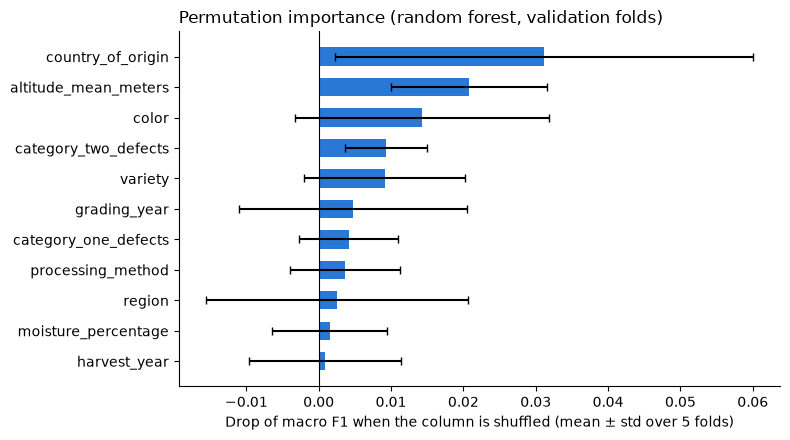

,mean,std
harvest_year,0.001,0.011
moisture_percentage,0.002,0.008
region,0.003,0.018
processing_method,0.004,0.008
category_one_defects,0.004,0.007
grading_year,0.005,0.016
variety,0.009,0.011
category_two_defects,0.009,0.006
color,0.014,0.018
altitude_mean_meters,0.021,0.011


In [26]:
fold_importances = []
for train_idx, val_idx in cv.split(X_train, y_train):
    model = clone(final_model).fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(model, X_train.iloc[val_idx], y_train.iloc[val_idx],
                                    scoring="f1_macro", n_repeats=10, random_state=42, n_jobs=-1)
    fold_importances.append(result.importances_mean)

importance = pd.DataFrame(fold_importances, columns=X_train.columns)
importance = importance.agg(["mean", "std"]).T.sort_values("mean")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance["mean"], xerr=importance["std"], color="#2a78d6", height=0.6, capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Drop of macro F1 when the column is shuffled (mean ± std over 5 folds)")
ax.set_title("Permutation importance (random forest, validation folds)", loc="left")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("./../report/figures/permutation_importance.pdf")
plt.show()
importance.round(3)

- `country_of_origin` (−0.031 of macro F1 when shuffled) and `altitude_mean_meters` (−0.021) are the two
  features the forest really uses. This matches the week 2 exploration (altitude and country were the clearest signals).
- `category_two_defects` is small (−0.009) but positive in every fold (std 0.006): a weak but stable signal,
  consistent with `Commercial` lots having more defects.
- `color` comes third on average (−0.014), but with a larger standard deviation (0.018), so it is uncertain.
  In week 2 we saw that `color` is missing much more often for `Exemplary` lots: part of its importance may
  come from the *missingness* (the `"Unknown"` category), not from the colour itself. This is a property of how
  the CQI data was collected, and it may not hold for new lots.
- The other features have an importance smaller than its standard deviation: we cannot say they help.
  `harvest_year` and `moisture_percentage` are close to 0, as expected from the exploration.
  `region` is also weak, probably because most of its 356 values are grouped as rare by the encoder.
- The country standard deviation is large (0.029): its importance depends a lot on which lots are in the fold.

## Conclusion

| | Macro F1 (CV) | `Commercial` recall (CV) | Macro F1 (test) |
|---|---|---|---|
| Logistic regression (baseline) | 0.46 ± 0.03 | 0.64 ± 0.05 | 0.52 [0.45, 0.58] |
| Random forest (final) | 0.54 ± 0.05 | 0.56 ± 0.12 | 0.63 [0.55, 0.71] |

- **Models that help:** random forests (alone, with SMOTE or inside a voting) beat the baseline by about
  0.08–0.09 macro F1, and the gain is significant with the corrected t-test. A likely reason (not tested)
  is that trees can use interactions, like "high altitude *in this country*", that a linear model cannot.
- **What did not help:** tuning the logistic regression, feature selection (filter, wrapper, embedded),
  SMOTE instead of class weights, stacking, and single trees or bagged trees.
- **Our measurable goal from week 1 was a CV macro F1 ≥ 0.55.** We reach 0.54 ± 0.05: close, but not reached.
- **Trade-off:** the gain comes mostly from the `Specialty` class and from fewer false alarms. The forest finds
  fewer `Commercial` and `Exemplary` lots than the baseline. For a buyer who wants to catch every bad lot,
  the baseline is still useful.
- **Failure mode:** the model depends mainly on country and altitude. Two lots from the same country and altitude
  but with different care at the farm will get almost the same prediction: the data does not describe the work of
  the producer, which is a large part of the cup quality. And the missing-value signal (`color`) may not
  hold for lots graded in another way.

Next steps (week 4): add the contextual country dataset; tune the decision threshold of the forest to
recover `Commercial` recall if the buyer's costs require it; check the calibration of the predicted probabilities.